# 02_2. Univariate strength / Одномерная сила связи

**EN.** Steps 2–3 of the methodology. For every one of the 59 candidates and the task Y1 (early default; population: loans current at t and never in default before t, delinquency history excluded, see 02_1) we measure how strongly the feature *alone* separates loans with and without an event:

- **WoE binning and IV.** The feature is cut into bins (up to 10, plus a bin for missing). For each bin, **WoE** (weight of evidence) = ln(share of "goods" in the bin / share of "bads" in the bin), where goods are loans without an event and bads — with an event. WoE > 0: the bin is safer than average; WoE < 0: riskier. **IV** (information value) = Σ (share of goods − share of bads) × WoE — the total separating power. Usual scale: < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, > 0.3 strong, **> 0.5 suspicious** (check for leakage).
- **KS** (Kolmogorov–Smirnov) — the largest gap between the cumulative distributions of bads and goods along the feature; from 0 (no separation) to 1.
- **χ² test and Cramér's V** — is the event rate the same in every bin? χ² gives a p-value, V (0…1) the size of the effect. p-values are adjusted for testing many features at once by **Benjamini–Hochberg** (controls the share of false discoveries).

**Binning rule.** Every bin must hold at least 0.5 % of the population and 30 events. Exception: a *rare significant* value range — at least 30 events and an event rate at least twice that of its neighbours (e.g. a rare missing value: `prepayment_penalty_indicator` is missing in only 67 sampled rows, but 40 of them have an event, against 0.12 % overall) — keeps its own bin. As a sensitivity check the whole step is repeated with the binning of the first trial run (bins down to 0.05 %, no exception), see section 8.

Bins are fitted **on train only** (full train, all events + 20 % of non-events with weight 1/0.2 = 5) and then applied unchanged to validation, so the validation numbers are an honest out-of-time check. Validation excludes the 2017-hurricane rows; with them is a sensitivity check.

**RU.** Шаги 2–3 методологии. Для каждого из 59 кандидатов и задачи Y1 (ранний дефолт; популяция — кредиты без просрочки на t, не бывшие в дефолте до t, история просрочек исключена, см. 02_1) измеряем, насколько хорошо признак *сам по себе* разделяет кредиты с событием и без:

- **WoE-биннинг и IV.** Признак разбивается на корзины (до 10 плюс корзина для пропусков). Для каждой корзины **WoE** (weight of evidence, «вес свидетельства») = ln(доля «хороших» в корзине / доля «плохих» в корзине); хорошие — кредиты без события, плохие — с событием. WoE > 0 — корзина безопаснее среднего, WoE < 0 — рискованнее. **IV** (information value, информационная ценность) = Σ (доля хороших − доля плохих) × WoE — общая разделяющая сила. Обычная шкала: < 0,02 бесполезен, 0,02–0,1 слабый, 0,1–0,3 средний, > 0,3 сильный, **> 0,5 подозрительно** (проверить на утечку).
- **KS** (Колмогоров–Смирнов) — наибольший разрыв между накопленными распределениями плохих и хороших вдоль признака; от 0 (не разделяет) до 1.
- **Тест χ² и V Крамера** — одинакова ли доля событий во всех корзинах? χ² даёт p-value, V (0…1) — размер эффекта. p-value поправляются на множественность по **Бенджамини–Хохбергу** (контроль доли ложных открытий).

**Правило биннинга.** В каждой корзине должно быть не меньше 0,5 % популяции и 30 событий. Исключение — *редкое значимое* значение: не меньше 30 событий и доля событий хотя бы вдвое отличается от соседних корзин (например, редкий пропуск: `prepayment_penalty_indicator` пуст лишь в 67 строках выборки, но у 40 из них есть событие против 0,12 % в среднем). Такое значение получает отдельную корзину. Для проверки чувствительности весь шаг повторяется с биннингом первого пробного прогона (корзины до 0,05 %, без исключения), см. раздел 8.

Корзины строятся **только на train** (полный train, все события + 20 % кредитов без события с весом 1/0,2 = 5) и без изменений применяются к validation, поэтому цифры на validation — честная проверка на другом периоде. Из validation исключены наблюдения с ураганами 2017 г.; с ними — проверка чувствительности.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.data.features import COLUMNS, candidate_features, categorical_features
from xai_ews.features.data import TASKS, event_counts, load_train, load_validation
from xai_ews.features.univariate import bh_adjust, univariate_apply, univariate_train
from xai_ews.features.woe import bin_table, save_binners
from xai_ews.paths import FEATURE_SELECTION_DIR, STAGE2_INTERIM_DIR

CFG = feature_config()
RULES = CFG["rules"]["univariate"]
FEATS = candidate_features()
CATS = set(categorical_features())
BINNING_SENS = {**CFG["binning"], **CFG["binning_sensitivity"]}
print(CFG["binning"])
print("sensitivity:", CFG["binning_sensitivity"])
print(RULES)

{'prebins': 20, 'max_bins': 10, 'min_bin_share': 0.005, 'min_bin_events': 30, 'rare_bin_rate_ratio': 2.0, 'rare_category_share': 0.001, 'smoothing': 0.5}
sensitivity: {'min_bin_share': 0.0005, 'rare_bin_rate_ratio': None}
{'iv_min': 0.02, 'iv_leak_check': 0.5, 'decide_by': 'effect_size'}


### 1. Fit the bins on train, apply to validation / Корзины на train, применение к validation

**EN.** We load the Y1 train population, fit the bins and compute the train metrics, free the memory, then load validation (without and with the hurricane rows) and recompute IV / KS / AUC with the *train* bins. The counts table shows events per observation and per unique loan. `weighted_rows` is the population size that the weighted train represents. This cell takes a few minutes.

**RU.** Загружаем популяцию Y1 в train, строим корзины и считаем метрики на train, освобождаем память, затем загружаем validation (без ураганов и с ними) и пересчитываем IV / KS / AUC с корзинами *train*. Таблица показывает события по наблюдениям и по уникальным кредитам. `weighted_rows` — размер популяции, которую представляет взвешенный train. Ячейка выполняется несколько минут.

In [2]:
counts, metrics, bins, sens = [], [], [], []
for task in TASKS:
    tr = load_train(task)
    counts.append({"task": task, "sample": "train (r = 0.2, weights 1/r)", **event_counts(tr, task)})
    binners, m_tr = univariate_train(tr, task, FEATS, CATS, CFG["binning"])
    save_binners(binners, STAGE2_INTERIM_DIR / f"woe_binners_{task}.json")
    binners_s, m_tr_s = univariate_train(tr, task, FEATS, CATS, BINNING_SENS)   # sensitivity binning
    save_binners(binners_s, STAGE2_INTERIM_DIR / f"woe_binners_{task}_sens.json")
    bt = pd.concat([bin_table(b, tr[f].to_numpy(), tr[task].to_numpy(), tr["sample_weight"].to_numpy())
                    for f, b in binners.items()])
    del tr; gc.collect()
    va = load_validation(task)
    counts.append({"task": task, "sample": "validation (no hurricanes)", **event_counts(va, task)})
    m_va = univariate_apply(va, task, binners, "val")
    m_va_s = univariate_apply(va, task, binners_s, "val")
    sens.append(m_tr_s[["feature", "n_bins", "iv_train"]].merge(m_va_s[["feature", "iv_val"]], on="feature").assign(task=task))
    bv = pd.concat([bin_table(b, va[f].to_numpy(), va[task].to_numpy(), va["sample_weight"].to_numpy())
                    for f, b in binners.items()])[["feature", "bin", "rows", "events", "share", "event_rate"]]
    del va; gc.collect()
    vh = load_validation(task, hurricanes=True)
    counts.append({"task": task, "sample": "validation (with hurricanes)", **event_counts(vh, task)})
    m_vh = univariate_apply(vh, task, binners, "val_hur")
    del vh; gc.collect()
    metrics.append(m_tr.merge(m_va, on="feature").merge(m_vh, on="feature").assign(task=task))
    bins.append(bt.merge(bv, on=["feature", "bin"], how="left", suffixes=("_train", "_val")).assign(task=task))

counts = pd.DataFrame(counts).set_index(["task", "sample"])
uni = pd.concat(metrics, ignore_index=True)
bins = pd.concat(bins, ignore_index=True)
counts

rows    loans   weighted_rows  events_obs  event_loans  event_rate_weighted
task sample                                                                                                      
y1   train (r = 0.2, weights 1/r)  2294292  1239248 11,415,212.0000       14062         7068               0.0012
     validation (no hurricanes)    1854380   610679  1,854,380.0000        3706         2259               0.0020
     validation (with hurricanes)  2010979   629463  2,010,979.0000        6472         3818               0.0032

**EN. How to read.** Train: ~2.3 M sampled rows (1.24 M loans) represent ~11.4 M observations of the population. There are 14,062 events on 7,068 loans; the weighted event rate is 0.12 %. Validation without the hurricane rows: 1.85 M observations of 610,679 loans, 3,706 events on 2,259 loans (0.20 %); with them 6,472 events on 3,818 loans (0.32 %). The validation period is riskier than train. Every validation date contains a loan at most once, but a loan appears at up to 4 dates, so loans < observations here too.

**RU. Как читать.** Train: ~2,3 млн строк выборки (1,24 млн кредитов) представляют ~11,4 млн наблюдений популяции. Событий 14 062 на 7 068 кредитах, взвешенная доля событий — 0,12 %. Validation без ураганов: 1,85 млн наблюдений по 610 679 кредитам, 3 706 событий на 2 259 кредитах (0,20 %); с ураганами — 6 472 события на 3 818 кредитах (0,32 %). Период validation рискованнее, чем train. На одной дате validation кредит встречается не больше одного раза, но дат четыре, поэтому и здесь кредитов меньше, чем наблюдений.

### 2. Multiple testing: χ² p-values with Benjamini–Hochberg / Множественная проверка: p-value χ² с поправкой БХ

**EN.** The χ² test asks whether the event rate differs between the bins of a feature. It is run on the *unweighted* train counts: because negatives were sampled depending only on the label, "feature independent of the event" holds in the sample exactly when it holds in the population. Then BH adjusts the p-values of all features together.

**RU.** Тест χ² проверяет, различается ли доля событий между корзинами признака. Он считается по *невзвешенным* частотам train: отрицательные отбирались только по метке, поэтому «признак не связан с событием» в выборке верно ровно тогда, когда это верно в популяции. Затем p-value всех признаков поправляются по БХ вместе.

In [3]:
uni["chi2_p_bh"] = bh_adjust(uni["chi2_p"].where(uni["chi2_dof"] > 0))
informative = uni["chi2_dof"] > 0
print(f"tests run: {informative.sum()}; significant after BH at 5 %: {(uni['chi2_p_bh'] < 0.05).sum()}")
print(f"of them with IV < 0.02 (significant but negligible): {((uni['chi2_p_bh'] < 0.05) & (uni['iv_train'] < RULES['iv_min'])).sum()}")
uni.loc[informative].sort_values("chi2_p_bh", ascending=False).head(8)[["feature", "task", "iv_train", "cramers_v_train", "chi2_train", "chi2_p_bh"]]

tests run: 50; significant after BH at 5 %: 50
of them with IV < 0.02 (significant but negligible): 7


,feature,task,iv_train,cramers_v_train,chi2_train,chi2_p_bh
14,number_of_units,y1,0.0008,0.0010,10.6913,0.0011
23,relocation_mortgage_indicator,y1,0.0031,0.0016,30.9347,0.0000
11,channel,y1,0.0046,0.0024,63.7709,0.0000
21,high_balance_loan_indicator,y1,0.0085,0.0026,76.2327,0.0000
51,unemployment_chg_6m,y1,0.0121,0.0038,164.6648,0.0000
45,n_upb_increase_12m,y1,0.0067,0.0036,145.2769,0.0000
54,unemployment_chg_12m_rel_us,y1,0.0218,0.0050,287.3862,0.0000
50,unemployment,y1,0.0227,0.0051,293.3200,0.0000


**EN. How to read.** With ~2.3 M rows every test that can be run is "significant": all 50 (the other 9 features have a single bin), including 7 features whose IV is below 0.02 — a statistically real but practically useless difference. This is why the methodology decides by **effect size** (IV), not by p-value. Note also that rows of one loan are dependent, so these p-values are even too optimistic. Cramér's V is tiny: at most 0.05 for every feature, because events are rare (0.12 %). With a rare event V is a poor measure of usefulness; IV and KS are better.

**RU. Как читать.** При ~2,3 млн строк «значимы» все тесты, которые можно провести: все 50 (у остальных 9 признаков одна корзина), включая 7 признаков с IV < 0,02: различие статистически реально, но практически бесполезно. Поэтому по методологии решение принимается по **размеру эффекта** (IV), а не по p-value. Кроме того, наблюдения одного кредита зависимы, и эти p-value ещё и завышают уверенность. V Крамера очень мал: не больше 0,05 у всех признаков, потому что события редки (0,12 %). При редком событии V плохо отражает полезность, лучше смотреть на IV и KS.

### 3. Information Value / Информационная ценность

**EN.** IV on train (log scale). The dashed line is the 0.02 threshold, the dotted one — 0.5 (leakage check).

**RU.** IV на train (логарифмическая шкала). Пунктир — порог 0,02, точки — 0,5 (проверка на утечку).

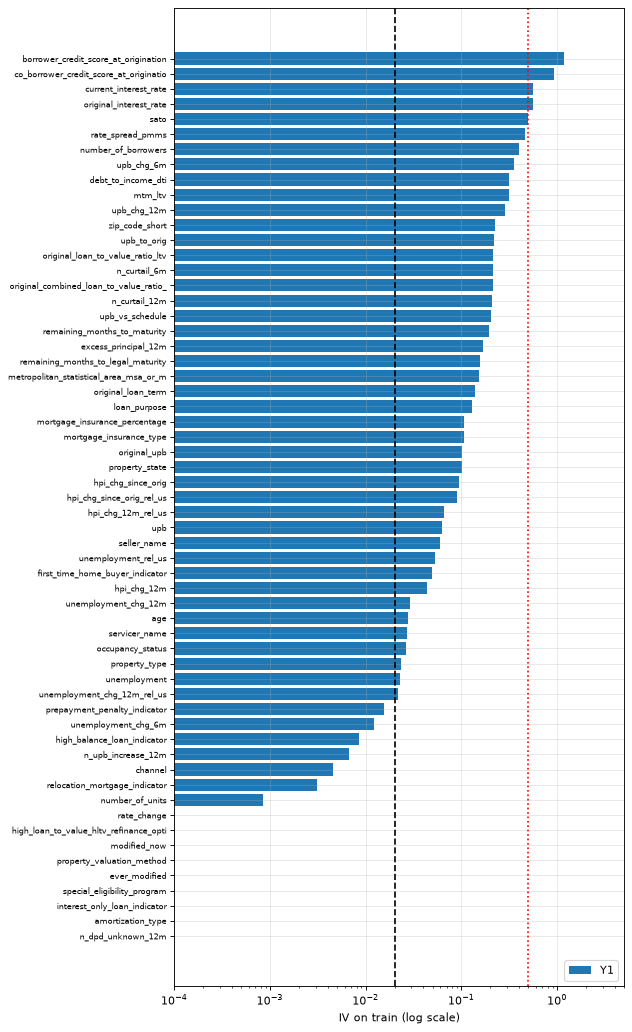

In [4]:
iv = uni.pivot(index="feature", columns="task", values="iv_train")
iv = iv.loc[iv.max(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 13))
y = np.arange(len(iv))
for k, t in enumerate(TASKS):
    ax.barh(y + 0.8 * (k - (len(TASKS) - 1) / 2) / len(TASKS), iv[t].clip(lower=1e-4),
            height=0.8 / len(TASKS), label=t.upper())
ax.set_yticks(y, [f[:38] for f in iv.index], fontsize=7)
ax.set_xscale("log"); ax.set_xlim(1e-4, 5)
ax.axvline(RULES["iv_min"], ls="--", c="k"); ax.axvline(RULES["iv_leak_check"], ls=":", c="r")
ax.set_xlabel("IV on train (log scale)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**EN. How to read.** Without delinquency history the top of the chart belongs to **origination data**: the borrower and co-borrower credit scores (IV 1.18 and 0.93), then the price of the loan — current and original interest rate (0.55 each), SATO (0.50), spread to the market rate (0.46) — and the number of borrowers (0.40). The strongest dynamic signals are the **payment pace** (`upb_chg_6m` 0.35, `upb_chg_12m` 0.29, `upb_vs_schedule` 0.20) and **partial prepayments** (`n_curtail_*` 0.21), close to DTI (0.32), mark-to-market LTV (0.31) and remaining term (0.19). No feature has IV above 1.18.

**RU. Как читать.** Без истории просрочек верх графика занимают **данные при выдаче**: рейтинги заёмщика и созаёмщика (IV 1,18 и 0,93), затем цена кредита — текущая и исходная ставка (по 0,55), SATO (0,50), спред к рыночной ставке (0,46) — и число заёмщиков (0,40). Сильнейшие динамические сигналы — **темп погашения** (`upb_chg_6m` 0,35, `upb_chg_12m` 0,29, `upb_vs_schedule` 0,20) и **частичные досрочные погашения** (`n_curtail_*` 0,21), рядом с DTI (0,32), текущим LTV (0,31) и остатком срока (0,19). Ни у одного признака IV не выше 1,18.

In [5]:
wide = uni.pivot(index="feature", columns="task", values=["iv_train", "iv_val", "ks_train", "ks_val", "auc_woe_val"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide["iv_max"] = wide[[f"iv_train_{t}" for t in TASKS]].max(axis=1)
wide = wide.sort_values("iv_max", ascending=False)
wide.head(25).drop(columns="iv_max")

,iv_train_y1,iv_val_y1,ks_train_y1,ks_val_y1,auc_woe_val_y1
feature,,,,,
borrower_credit_score_at_origination,1.1799,1.2286,0.4466,0.4536,0.7893
co_borrower_credit_score_at_origination,0.9260,0.8365,0.3744,0.3409,0.6965
current_interest_rate,0.5543,0.5226,0.3062,0.2878,0.6953
original_interest_rate,0.5543,0.5226,0.3062,0.2878,0.6953
sato,0.5011,0.4914,0.2983,0.2926,0.6932
rate_spread_pmms,0.4616,0.3165,0.2659,0.2114,0.6499
number_of_borrowers,0.4000,0.2882,0.3063,0.2585,0.6292
upb_chg_6m,0.3501,0.3916,0.2228,0.2367,0.6643
debt_to_income_dti,0.3156,0.2466,0.2281,0.1999,0.6345


**EN. How to read.** `iv_val` uses the train bins on the validation period. For most features it is close to `iv_train` — the signal holds out of time; for the payment-pace features it is even higher (`upb_chg_12m` 0.29 → 0.36). The exceptions (fine geography, loan size, macro changes) are discussed in section 6. KS of the strongest single feature, the credit score, is 0.45 on train and on validation (AUC 0.79); the next ones have KS 0.27–0.37. `auc_woe_val` is the AUC of the single feature on validation.

**RU. Как читать.** `iv_val` — IV корзин train на периоде validation. У большинства признаков он близок к `iv_train`: сигнал сохраняется во времени; у признаков темпа погашения он даже выше (`upb_chg_12m` 0,29 → 0,36). Исключения (мелкая география, размер кредита, изменения макро) разобраны в разделе 6. KS сильнейшего признака — кредитного рейтинга — 0,45 на train и на validation (AUC 0,79); у следующих KS 0,27–0,37. `auc_woe_val` — AUC одного признака на validation.

### 4. IV above 0.5: leakage check / IV больше 0,5: проверка на утечку

**EN.** A very high IV can mean that the feature "knows the future". For each such feature we check its *temporal type* from the column register: only information up to date t is allowed (`static_origination`, `dynamic_at_t`, `trailing_to_t`, `macro_lagged`). Anything using months after t would be leakage.

**RU.** Очень высокий IV может означать, что признак «знает будущее». Для каждого такого признака проверяем *временной тип* по реестру колонок: допустима только информация до даты t (`static_origination`, `dynamic_at_t`, `trailing_to_t`, `macro_lagged`). Всё, что использует месяцы после t, было бы утечкой.

In [6]:
hi = wide[wide["iv_max"] > RULES["iv_leak_check"]][[f"iv_{s}_{t}" for s in ("train", "val") for t in TASKS]].copy()
hi["temporal"] = [COLUMNS[f].temporal for f in hi.index]
hi["group"] = [COLUMNS[f].group for f in hi.index]
print("future_window features among them:", (hi["temporal"] == "future_window").sum())
hi

future_window features among them: 0


,iv_train_y1,iv_val_y1,temporal,group
feature,,,,
borrower_credit_score_at_origination,1.1799,1.2286,static_origination,borrower
co_borrower_credit_score_at_origination,0.9260,0.8365,static_origination,borrower
current_interest_rate,0.5543,0.5226,dynamic_at_t,state_at_t
original_interest_rate,0.5543,0.5226,static_origination,loan
sato,0.5011,0.4914,static_origination,macro


**EN. Conclusion.** None of the five features with IV above 0.5 uses months after t, and all are expected:
1. **Credit scores at origination** — borrower (1.18) and co-borrower (0.93): the classic strongest predictors.
2. **Price of the loan** — original and current interest rate (0.55 each) and SATO, the spread over the market rate at origination (0.50): a higher rate reflects the risk the lender saw at origination. `current_interest_rate` is the only dynamic one, but for a fixed-rate loan it differs from the original rate only after a modification, which is very rare.
IV stays as high on validation (0.49–1.23), so these are not artefacts of the train period. The stage-1 leakage check (a CatBoost model on all 59 candidates, AUC 0.82, far below 0.97) covered these features too.

**RU. Вывод.** Ни один из пяти признаков с IV выше 0,5 не использует месяцы после t, и все они ожидаемы:
1. **Кредитные рейтинги при выдаче** — заёмщика (1,18) и созаёмщика (0,93): классические сильнейшие предикторы.
2. **Цена кредита** — исходная и текущая ставка (по 0,55) и SATO, спред к рыночной ставке при выдаче (0,50): более высокая ставка отражает риск, который кредитор видел при выдаче. `current_interest_rate` — единственный динамический из них, но у кредита с фиксированной ставкой она отличается от исходной только после модификации, а это очень редко.
На validation IV так же высок (0,49–1,23), то есть это не артефакт периода train. Проверка на утечку этапа 1 (CatBoost на всех 59 кандидатах, AUC 0,82, далеко от 0,97) охватывала и эти признаки.

### 5. How the bins look: examples / Как выглядят корзины: примеры

**EN.** Bins of a monotone numeric feature (credit score), of a rare missing value (`prepayment_penalty_indicator`, an example of the rare-bin rule) and of a categorical feature (loan purpose). `event_rate_train` is the weighted event rate in the bin (population scale), `event_rate_val` — on validation with the same bins.

**RU.** Корзины монотонного числового признака (кредитный рейтинг), редкого пропуска (`prepayment_penalty_indicator`, пример правила редких корзин) и категориального признака (цель кредита). `event_rate_train` — взвешенная доля событий в корзине (в масштабе популяции), `event_rate_val` — на validation с теми же корзинами.

In [7]:
cols = ["label", "rows_train", "events_train", "share_train", "event_rate_train", "woe_train", "iv_part", "event_rate_val"]
for f, t in [("borrower_credit_score_at_origination", "y1"), ("prepayment_penalty_indicator", "y1"), ("loan_purpose", "y1")]:
    print(f"--- {f}, {t.upper()}")
    display(bins.query("feature == @f and task == @t")[cols].set_index("label"))

--- borrower_credit_score_at_origination, Y1


,rows_train,events_train,share_train,event_rate_train,woe_train,iv_part,event_rate_val
label,,,,,,,
"(-inf, 682]",120163,4374,0.0511,0.0075,-1.8122,0.4717,0.0096
"(682, 703] + missing",116662,2099,0.0504,0.0037,-1.0888,0.1078,0.0053
"(703, 719]",114521,1408,0.0497,0.0025,-0.7023,0.0355,0.0030
"(719, 732]",115067,1059,0.0500,0.0019,-0.4097,0.0104,0.0024
"(732, 753]",229612,1567,0.1000,0.0014,-0.1081,0.0012,0.0019
"(753, 768]",239071,1084,0.1043,0.0009,0.3029,0.0083,0.0011
"(768, 774]",120842,407,0.0528,0.0007,0.6006,0.0143,0.0009
"(774, 779]",117451,301,0.0513,0.0005,0.8742,0.0262,0.0005
"(779, 805]",800651,1365,0.3502,0.0003,1.2840,0.3254,0.0004


--- prepayment_penalty_indicator, Y1


,rows_train,events_train,share_train,event_rate_train,woe_train,iv_part,event_rate_val
label,,,,,,,
NA + rare,67,40,0.0000,0.2286,-5.4903,0.0156,0.0000
N,2294225,14022,1.0000,0.0012,0.0029,0.0000,0.0020


--- loan_purpose, Y1


,rows_train,events_train,share_train,event_rate_train,woe_train,iv_part,event_rate_val
label,,,,,,,
C,519016,4309,0.2258,0.0017,-0.3057,0.0247,0.0025
P,832692,6297,0.3625,0.0015,-0.2115,0.0181,0.0023
R,942584,3456,0.4117,0.0007,0.5162,0.0857,0.0012


**EN. How to read.** Credit score: the event rate falls steadily from 0.75 % at 682 and below to 0.02 % above 805, WoE rises monotonically — the expected `-` sign. The few missing scores (0.05 %) are *not* remarkable (too few events or an event rate within 2× of the closest bin), so they join the bin with the closest event rate (683–703). `loan_purpose`: rate-and-term refinancing (R) is clearly the safest (0.07 %); cash-out (C, 0.17 %) is slightly riskier than purchase (P, 0.15 %), as expected. Validation rates are higher (the period is riskier) but the *order* of bins is the same. `prepayment_penalty_indicator` shows the rare-bin rule at work: only 67 train rows have a missing value, but 40 of them have an event (23 % on the population scale after weighting, against 0.12 % in the other bin), so the missing value keeps its own bin (WoE −5.5) although it holds far less than 0.5 % of the rows. This bin is the whole IV of the feature (0.016). On validation no row has a missing value (IV 0), and with IV below 0.02 the feature leaves at step 2: a rare bin can be real on train and still be of no use later. `modified_now` (the example of the previous run) now has a single bin (IV 0): almost all modified loans had been in default before t and are excluded from the population, and the few left are too few for a bin of their own. Only two bins are now below the 0.5 % floor: manufactured housing (`property_type` = MH, 0.37 % of rows) and this missing-value bin.

**RU. Как читать.** Рейтинг: доля событий плавно падает с 0,75 % при 682 и ниже до 0,02 % выше 805, WoE растёт монотонно — ожидаемый знак `-`. Немногие пропуски рейтинга (0,05 %) *не* выделяются (мало событий или доля событий отличается от ближайшей корзины меньше чем вдвое), поэтому они присоединены к корзине с ближайшей долей событий (683–703). `loan_purpose`: заметно безопаснее всего обычное рефинансирование (R, 0,07 %); cash-out (C, 0,17 %) немного рискованнее покупки (P, 0,15 %), как и ожидалось. На validation доли выше (период рискованнее), но *порядок* корзин тот же. `prepayment_penalty_indicator` показывает, как работает правило редких корзин: пропуск есть лишь в 67 строках train, но у 40 из них есть событие (23 % в масштабе популяции после взвешивания против 0,12 % в другой корзине), поэтому пропуск получает отдельную корзину (WoE −5,5), хотя в ней намного меньше 0,5 % строк. Эта корзина и даёт весь IV признака (0,016). На validation пропусков нет совсем (IV 0), а при IV ниже 0,02 признак выбывает на шаге 2: редкая корзина может быть реальной на train и всё равно бесполезной позже. У `modified_now` (пример предыдущего прогона) теперь одна корзина (IV 0): почти все модифицированные кредиты были в дефолте до t и исключены из популяции, а оставшихся слишком мало для отдельной корзины. Ниже порога 0,5 % теперь только две корзины: сборные дома (`property_type` = MH, 0,37 % строк) и эта корзина пропусков.

### 6. Out-of-time check and the hurricane sensitivity / Проверка на другом периоде и чувствительность к ураганам

**EN.** Ratio IV_val / IV_train: well below 1 means the train bins overfit or the relationship weakened. High-cardinality categoricals (ZIP3, MSA, state) are the usual suspects: their bins are formed by ordering many categories by their train event rate, which captures some noise. The last column shows how IV changes when the hurricane rows are kept in validation.

**RU.** Отношение IV_val / IV_train: значение намного меньше 1 означает переобучение корзин или ослабление связи. Обычные подозреваемые — категориальные признаки с большим числом значений (ZIP3, MSA, штат): их корзины формируются упорядочиванием множества категорий по доле событий на train и захватывают часть шума. Последняя колонка показывает, как меняется IV, если оставить в validation наблюдения с ураганами.

In [8]:
chk = uni[uni["iv_train"] >= RULES["iv_min"]].assign(
    ratio_val_train=lambda d: d["iv_val"] / d["iv_train"],
    iv_val_with_hurricanes=lambda d: d["iv_val_hur"])
chk.sort_values("ratio_val_train").head(12)[["feature", "task", "iv_train", "iv_val", "ratio_val_train", "iv_val_with_hurricanes"]]

,feature,task,iv_train,iv_val,ratio_val_train,iv_val_with_hurricanes
52,unemployment_chg_12m,y1,0.0293,0.0030,0.1037,0.0831
54,unemployment_chg_12m_rel_us,y1,0.0218,0.0057,0.2617,0.0561
28,zip_code_short,y1,0.2260,0.0741,0.3279,0.2859
34,upb,y1,0.0631,0.0215,0.3412,0.0108
6,original_upb,y1,0.1019,0.0460,0.4517,0.0396
13,property_type,y1,0.0235,0.0108,0.4589,0.0157
48,hpi_chg_since_orig,y1,0.0944,0.0490,0.5194,0.1209
55,hpi_chg_12m_rel_us,y1,0.0651,0.0360,0.5537,0.1360
27,metropolitan_statistical_area_msa_or_metropolitan_statis...,y1,0.1530,0.0873,0.5707,0.4110
10,loan_purpose,y1,0.1285,0.0734,0.5716,0.0626


**EN. Conclusion.** Out of time the weakest are (a) **macro changes** — the 12-month change of unemployment keeps only ~10 % of its train IV (26 % for the change relative to the US), the house-price change since origination ~50 %; (b) **loan size** (`upb` 34 %, `original_upb` 45 %); (c) **fine geography** — ZIP3 keeps a third, MSA 57 %, state 63 %. Their train IV is partly noise or a period effect; the stability notebook (02_3) checks them formally. With the hurricane rows the IV of geography and local macro **jumps**: MSA from 0.087 to 0.41, ZIP3 from 0.074 to 0.29, state from 0.063 to 0.35, state unemployment from 0.014 to 0.53. The state "predicts" the hurricane, which confirms that these rows must be excluded: with them geography would look much better than it is.

**RU. Вывод.** На другом периоде слабее всего держатся (а) **изменения макро** — изменение безработицы за 12 мес. сохраняет лишь ~10 % IV train (26 % для изменения относительно США), изменение цен с даты выдачи — ~50 %; (б) **размер кредита** (`upb` 34 %, `original_upb` 45 %); (в) **мелкая география** — ZIP3 сохраняет треть, MSA 57 %, штат 63 %. Их IV на train отчасти шум или эффект периода; формально их проверяет ноутбук стабильности (02_3). С наблюдениями урагана IV географии и местного макро **резко растёт**: MSA с 0,087 до 0,41, ZIP3 с 0,074 до 0,29, штат с 0,063 до 0,35, безработица штата с 0,014 до 0,53. Штат «угадывает» ураган, что подтверждает, что эти строки нужно исключить: с ними география выглядела бы намного лучше, чем она есть.

### 7. Decision of step 2: IV ≥ 0.02 / Решение шага 2: IV ≥ 0,02

**EN.** A feature passes if its train IV is at least 0.02. Features failing it carry practically no univariate information. They are not thrown away silently: the model-importance notebook (02_5) can still show a feature that only works in interactions, but by default they leave here.

**RU.** Признак проходит, если его IV на train не меньше 0,02. Не прошедшие практически не несут информации сами по себе. Они не выбрасываются незаметно: ноутбук важности (02_5) ещё может показать признак, работающий только во взаимодействиях, но по умолчанию они выбывают здесь.

In [9]:
wide["pass_iv"] = wide["iv_max"] >= RULES["iv_min"]
wide["leak_check"] = wide["iv_max"] > RULES["iv_leak_check"]
uni_out = uni.merge(wide[["iv_max", "pass_iv", "leak_check"]], left_on="feature", right_index=True)
uni_out.to_csv(FEATURE_SELECTION_DIR / "univariate.csv", index=False)
bins.to_csv(FEATURE_SELECTION_DIR / "woe_bins.csv", index=False)
print(f"pass: {wide['pass_iv'].sum()} of {len(wide)}; fail: {(~wide['pass_iv']).sum()}")
wide.loc[~wide["pass_iv"], [f"iv_{s}_{t}" for s in ("train", "val") for t in TASKS]]

pass: 43 of 59; fail: 16


,iv_train_y1,iv_val_y1
feature,,
prepayment_penalty_indicator,0.0156,0.0000
unemployment_chg_6m,0.0121,0.0077
high_balance_loan_indicator,0.0085,0.0037
n_upb_increase_12m,0.0067,0.0113
channel,0.0046,0.0000
relocation_mortgage_indicator,0.0031,0.0047
number_of_units,0.0008,0.0006
special_eligibility_program,0.0000,0.0089
rate_change,0.0000,0.0000


**EN. Conclusion of step 2.** 43 of 59 features pass, 16 fail:
- **no variation in train** (9): `amortization_type`, `interest_only_loan_indicator`, `high_loan_to_value_hltv_refinance_option_indicator`, `special_eligibility_program`, `property_valuation_method`, `n_dpd_unknown_12m` and the **modification features** `modified_now`, `ever_modified`, `rate_change` (one bin, IV 0): almost all modified loans had been in default before t and are now excluded from the population;
- **almost no variation** (1): `prepayment_penalty_indicator` (train IV 0.016 comes from 67 rows with a missing value; 0.000 on validation);
- **genuinely weak** (4): channel, number of units, relocation, high-balance flag (IV < 0.01, on validation too);
- **months with a balance increase** `n_upb_increase_12m` (IV 0.007);
- the **6-month change of unemployment** (IV 0.012).
**Loan age** now passes (IV 0.028 on train, 0.068 on validation). All IVs, bins and p-values are saved to `reports/feature_selection/univariate.csv` and `woe_bins.csv`; the train bins (JSON) to `data/interim/stage2/`.

**RU. Вывод шага 2.** Из 59 признаков проходят 43, не проходят 16:
- **нет вариации в train** (9): `amortization_type`, `interest_only_loan_indicator`, `high_loan_to_value_hltv_refinance_option_indicator`, `special_eligibility_program`, `property_valuation_method`, `n_dpd_unknown_12m` и **признаки модификации** `modified_now`, `ever_modified`, `rate_change` (одна корзина, IV 0): почти все модифицированные кредиты были в дефолте до t и теперь исключены из популяции;
- **почти нет вариации** (1): `prepayment_penalty_indicator` (IV 0,016 на train дают 67 строк с пропуском; на validation 0,000);
- **действительно слабые** (4): канал, число квартир, переезд, флаг high balance (IV < 0,01, и на validation тоже);
- **число месяцев с ростом остатка** `n_upb_increase_12m` (IV 0,007);
- **изменение безработицы за 6 месяцев** (IV 0,012).
**Возраст кредита** теперь проходит (IV 0,028 на train, 0,068 на validation). Все IV, корзины и p-value сохранены в `reports/feature_selection/univariate.csv` и `woe_bins.csv`, корзины train (JSON) — в `data/interim/stage2/`.

### 8. Sensitivity: binning of the first trial run / Чувствительность: биннинг первого пробного прогона

**EN.** The first trial used bins down to 0.05 % of the population without the rare-bin exception (rare missing values joined the largest bin). Here: IV under both binnings and whether the step-2 decision (IV ≥ 0.02) is the same. The comparison continues in 02_3 (PSI) and 02_4 (redundancy), where the decisions up to step 5 are compared.

**RU.** В первом пробном прогоне корзины были до 0,05 % популяции без исключения для редких значений (редкие пропуски присоединялись к самой большой корзине). Здесь — IV при обоих способах и совпадает ли решение шага 2 (IV ≥ 0,02). Сравнение продолжается в 02_3 (PSI) и 02_4 (дубли), где сравниваются решения до шага 5 включительно.

In [10]:
sens = pd.concat(sens, ignore_index=True)
cmp_ = uni[["feature", "task", "n_bins", "iv_train", "iv_val"]].merge(sens, on=["feature", "task"], suffixes=("", "_sens"))
pass_main = cmp_.groupby("feature")["iv_train"].max() >= RULES["iv_min"]
pass_sens = cmp_.groupby("feature")["iv_train_sens"].max() >= RULES["iv_min"]
cmp_.to_csv(FEATURE_SELECTION_DIR / "binning_sensitivity_univariate.csv", index=False)
print(f"step-2 decision differs for {(pass_main != pass_sens).sum()} of {len(pass_main)} features:",
      pass_main.index[pass_main != pass_sens].tolist())
cmp_["iv_change"] = cmp_["iv_train_sens"] - cmp_["iv_train"]
cmp_.reindex(cmp_["iv_change"].abs().sort_values(ascending=False).index).head(12)[
    ["feature", "task", "n_bins", "n_bins_sens", "iv_train", "iv_train_sens", "iv_val", "iv_val_sens"]]

step-2 decision differs for 0 of 59 features: []


,feature,task,n_bins,n_bins_sens,iv_train,iv_train_sens,iv_val,iv_val_sens
19,prepayment_penalty_indicator,y1,2,1,0.0156,0.0000,0.0000,0.0000
47,mtm_ltv,y1,10,10,0.3103,0.3089,0.2951,0.2949
14,number_of_units,y1,2,3,0.0008,0.0020,0.0006,0.0006
52,unemployment_chg_12m,y1,10,10,0.0293,0.0286,0.0030,0.0033
51,unemployment_chg_6m,y1,10,10,0.0121,0.0116,0.0077,0.0076
55,hpi_chg_12m_rel_us,y1,10,10,0.0651,0.0646,0.0360,0.0359
48,hpi_chg_since_orig,y1,10,10,0.0944,0.0939,0.0490,0.0489
54,unemployment_chg_12m_rel_us,y1,10,10,0.0218,0.0214,0.0057,0.0057
49,hpi_chg_12m,y1,10,10,0.0439,0.0435,0.0341,0.0340
2,debt_to_income_dti,y1,10,10,0.3156,0.3152,0.2466,0.2462


**EN. Conclusion.** The two binnings give the same step-2 decision for all 59 features. The only visible difference is the small risky bin of `prepayment_penalty_indicator`: without the rare-bin rule its 67 rows with a missing value join the main bin (IV 0.016 → 0), but it fails step 2 under either binning. The modification flags, which in the previous run depended on the rule, now have a single bin under both binnings. Elsewhere IV changes by at most 0.0014 (`mtm_ltv`) and no decision changes. Notebook 02_4 (section 7) compares the decisions up to step 5.

**RU. Вывод.** Оба способа биннинга дают одинаковое решение шага 2 для всех 59 признаков. Заметное отличие одно — маленькая рискованная корзина `prepayment_penalty_indicator`: без правила редких значений её 67 строк с пропуском присоединяются к основной корзине (IV 0,016 → 0), но признак не проходит шаг 2 при любом биннинге. Флаги модификации, которые в предыдущем прогоне зависели от этого правила, теперь при обоих способах имеют одну корзину. У остальных IV меняется не больше чем на 0,0014 (`mtm_ltv`), и ни одно решение не меняется. Ноутбук 02_4 (раздел 7) сравнивает решения до шага 5.